Load and merge the datasets

In [27]:
import io
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Styling for clean notebook plots
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["font.size"] = 11

df_meta = pd.read_csv(r"C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\data\metadata.csv")
df_gt = pd.read_csv(r"C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\data\ISIC_2024_Training_GroundTruth.csv")

# Join tables on 'isic_id'
df = df_meta.merge(df_gt, on="isic_id", how="left")

print(f"Successfully loaded and merged dataframe with shape: {df.shape}")

Successfully loaded and merged dataframe with shape: (218776, 41)


Corelation analysis and multicollinearity check

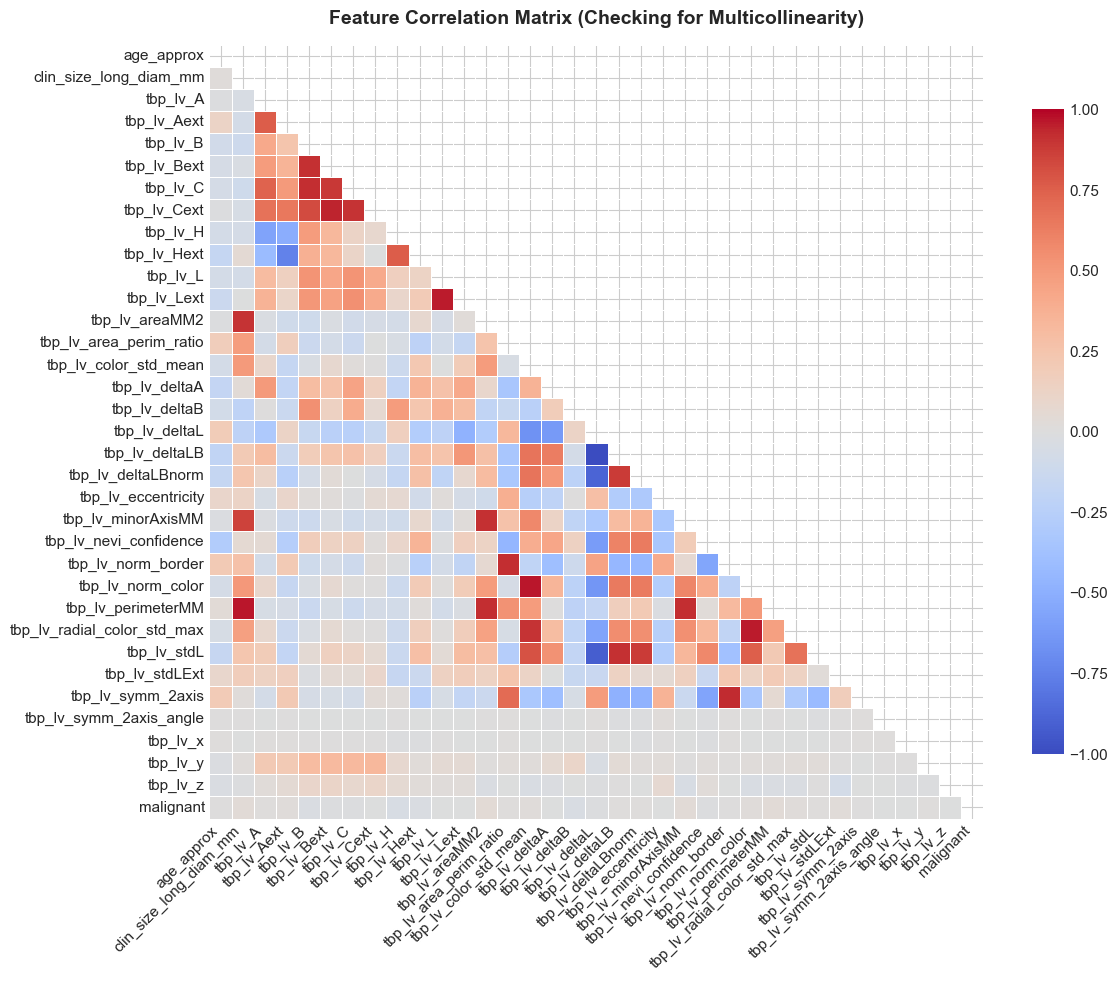


Top features correlated with 'malignant':
malignant                      1.000000
tbp_lv_areaMM2                 0.045086
tbp_lv_perimeterMM             0.036140
tbp_lv_minorAxisMM             0.034084
clin_size_long_diam_mm         0.031563
tbp_lv_stdLExt                 0.028600
tbp_lv_radial_color_std_max    0.020728
tbp_lv_color_std_mean          0.020683
tbp_lv_norm_color              0.018898
tbp_lv_Aext                    0.018713
Name: malignant, dtype: float64


In [28]:
# 1. Select only numeric columns
numeric_df = df.select_dtypes(include=[np.number])

# 2. Compute the correlation matrix
corr_matrix = numeric_df.corr()

# 3. Plot the correlation heatmap
plt.figure(figsize=(12, 10))

# Generate a mask for the upper triangle to avoid redundancy
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Draw the heatmap
sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap="coolwarm",
    vmax=1.0,
    vmin=-1.0,
    center=0,
    annot=False,  # Keep False if you have dozens of columns to avoid clutter
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
)

plt.title(
    "Feature Correlation Matrix (Checking for Multicollinearity)",
    fontsize=14,
    fontweight="bold",
    pad=15,
)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Optional: Print top features correlated with the target ('malignant') if present
if "malignant" in corr_matrix.columns:
  print("\nTop features correlated with 'malignant':")
  print(corr_matrix["malignant"].sort_values(ascending=False).head(10))

Summary Statistics for Numeric Metadata Columns

In [29]:
# 1. Generate descriptive statistics and transpose (.T) for easy reading
desc_stats = numeric_df.describe().T

# 2. Add missing counts and missing percentages for extra insight
desc_stats["missing_count"] = numeric_df.isnull().sum()
desc_stats["missing_pct"] = (numeric_df.isnull().mean() * 100).round(2)

# 3. Reorder columns to put missingness and basic stats upfront
cols = [
    "missing_count",
    "missing_pct",
    "count",
    "mean",
    "std",
    "min",
    "25%",
    "50%",
    "75%",
    "max",
]
desc_stats = desc_stats[[c for c in cols if c in desc_stats.columns]]

# Display the table cleanly in the notebook
display(desc_stats)

,missing_count,missing_pct,count,mean,std,min,25%,50%,75%,max
age_approx,0,0.0,218776.0,58.020601,13.565141,5.000000,50.000000,60.000000,70.000000,85.000000
clin_size_long_diam_mm,0,0.0,218776.0,3.929127,1.743771,1.000000,2.840000,3.370000,4.380000,28.400000
tbp_lv_A,0,0.0,218776.0,19.972093,3.997007,-2.487115,17.331400,19.798525,22.307125,45.438274
tbp_lv_Aext,0,0.0,218776.0,14.921490,3.535596,-1.906586,12.469481,14.717305,17.138210,35.930818
tbp_lv_B,0,0.0,218776.0,28.274773,5.270869,-0.730989,24.701593,28.166554,31.624913,52.420130
tbp_lv_Bext,0,0.0,218776.0,26.907564,4.477748,9.237066,23.846837,26.697052,29.673801,47.678020
tbp_lv_C,0,0.0,218776.0,34.779046,5.702923,7.715667,30.995956,34.814094,38.426813,58.765170
tbp_lv_Cext,0,0.0,218776.0,30.917492,4.829818,11.846520,27.656000,30.801509,33.963525,52.458730
tbp_lv_H,0,0.0,218776.0,54.651053,5.514522,-1.574164,51.555863,55.028283,58.298450,105.875784
tbp_lv_Hext,0,0.0,218776.0,60.991248,5.630937,28.436490,57.301768,61.108406,64.898746,95.768857


Inspect Unique Values of Non-Numerical Columns


In [15]:
cat_cols = df.select_dtypes(include=["object", "category"]).columns

for col in cat_cols:
  unique_vals = df[col].unique()
  print(f"Column: '{col}' ({len(unique_vals)} unique values)")
  print(list(unique_vals)[:15])  # Prints up to first 15 to keep output clean
  print("-" * 50)

Column: 'isic_id' (218776 unique values)
['ISIC_0015670', 'ISIC_0015845', 'ISIC_0015864', 'ISIC_0015902', 'ISIC_0024200', 'ISIC_0035502', 'ISIC_0051648', 'ISIC_0051665', 'ISIC_0051710', 'ISIC_0051758', 'ISIC_0051812', 'ISIC_0051822', 'ISIC_0051896', 'ISIC_0051897', 'ISIC_0051958']
--------------------------------------------------
Column: 'patient_id' (1039 unique values)
['IP_1235828', 'IP_8170065', 'IP_6724798', 'IP_4111386', 'IP_8313778', 'IP_3026693', 'IP_0218255', 'IP_7734648', 'IP_1307115', 'IP_2180091', 'IP_7792811', 'IP_4934005', 'IP_7438238', 'IP_5516884', 'IP_9726832']
--------------------------------------------------
Column: 'sex' (3 unique values)
['male', 'female', nan]
--------------------------------------------------
Column: 'anatom_site_general' (6 unique values)
['lower extremity', 'head/neck', 'posterior torso', 'anterior torso', 'upper extremity', nan]
--------------------------------------------------
Column: 'tbp_lv_location' (21 unique values)
['Right Leg - Uppe

Visualizing Challenge 1 — Severe Class Imbalance

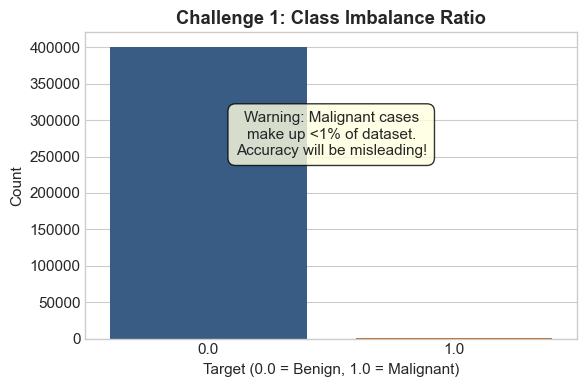

In [2]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(
    data=df, x="malignant", palette=["#2b5c8f", "#d95f02"], hue="malignant", legend=False
)
plt.title("Challenge 1: Class Imbalance Ratio", fontweight="bold")
plt.xlabel("Target (0.0 = Benign, 1.0 = Malignant)")
plt.ylabel("Count")

# Annotate warning
plt.text(
    0.5,
    0.6,
    "Warning: Malignant cases\nmake up <1% of dataset.\nAccuracy will be misleading!",
    transform=ax.transAxes,
    ha="center",
    bbox=dict(boxstyle="round,pad=0.5", fc="#ffffe0", alpha=0.8),
)

plt.tight_layout()
plt.show()

Visualizing Challenge 2 — Patient Age Distribution (Bell Curve/KDE)

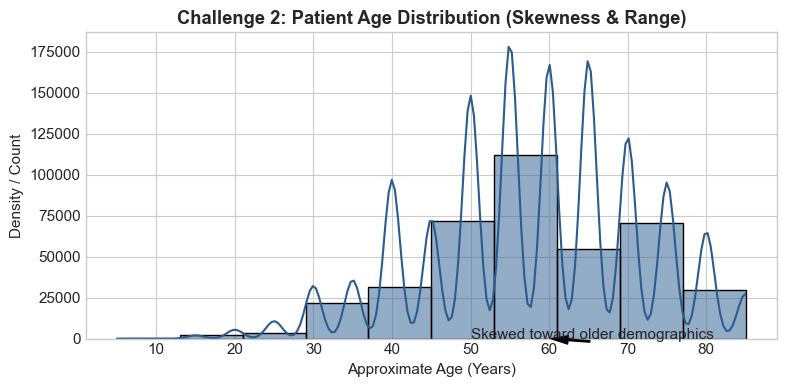

In [3]:
plt.figure(figsize=(8, 4))
sns.histplot(
    df["age_approx"].dropna(),
    kde=True,
    color="#2b5c8f",
    bins=10,
    edgecolor="black",
)
plt.title("Challenge 2: Patient Age Distribution (Skewness & Range)", fontweight="bold")
plt.xlabel("Approximate Age (Years)")
plt.ylabel("Density / Count")

# Highlight clinical distribution skew
plt.annotate(
    "Skewed toward older demographics",
    xy=(60, 1),
    xytext=(50, 1.5),
    arrowprops=dict(facecolor="black", shrink=0.05, width=1, headwidth=6),
)

plt.tight_layout()
plt.show()

Visualizing Challenge 3 — Lesion Size Outliers

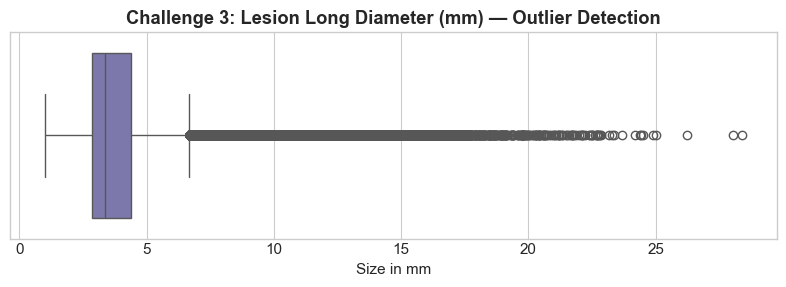

In [4]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df["clin_size_long_diam_mm"], color="#7570b3")
plt.title(
    "Challenge 3: Lesion Long Diameter (mm) — Outlier Detection", fontweight="bold"
)
plt.xlabel("Size in mm")

plt.tight_layout()
plt.show()

Visualizing Challenge 4 — Structural Missing Data in Supplements

C:\Users\Aim\AppData\Local\Temp\ipykernel_2072\4103614505.py:7: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:#e7298a'` for the same effect.

  sns.barplot(


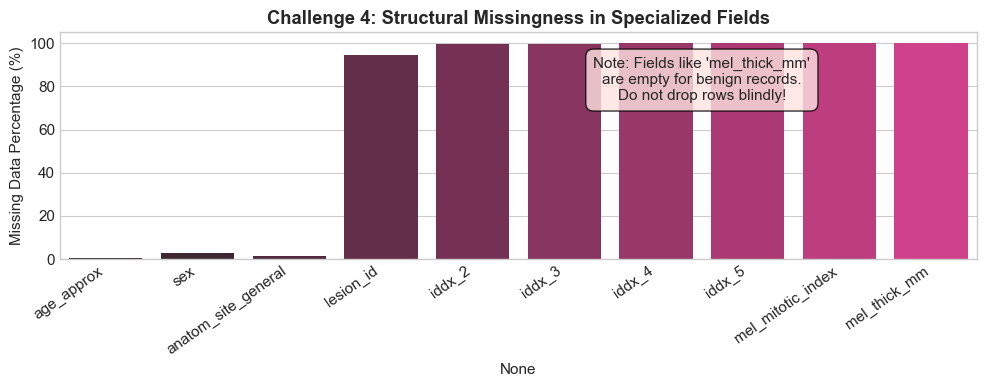

In [7]:
# Calculate percentage of missing values per column
missing_pct = df.isnull().mean() * 100
missing_pct = missing_pct[missing_pct > 0]  # Filter columns with missing data

if not missing_pct.empty:
  plt.figure(figsize=(10, 4))
  sns.barplot(
      x=missing_pct.index, y=missing_pct.values, color="#e7298a", hue=missing_pct.index, legend=False
  )
  plt.title(
      "Challenge 4: Structural Missingness in Specialized Fields", fontweight="bold"
  )
  plt.ylabel("Missing Data Percentage (%)")
  plt.xticks(rotation=35, ha="right")

  plt.text(
      0.7,
      0.7,
      "Note: Fields like 'mel_thick_mm'\nare empty for benign records.\nDo not drop rows blindly!",
      transform=plt.gca().transAxes,
      ha="center",
      bbox=dict(boxstyle="round,pad=0.5", fc="#ffe4e1", alpha=0.8),
  )

  plt.tight_layout()
  plt.show()
else:
  print("No missing values found in this sample slice.")

There are some missing values in the age column, all of these values will be replaced by median age so that it doesnt affect the models work process

In [23]:
# Path to your metadata file
import os

# Path to your metadata file
csv_path = r"C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\data\metadata.csv"  

if os.path.exists(csv_path):
  # 1. Load the metadata file
  df_meta = pd.read_csv(csv_path)

  if "age_approx" in df_meta.columns:
    missing_count = df_meta["age_approx"].isnull().sum()

    if missing_count > 0:
      # 2. Calculate median age (robust to outliers)
      median_age = df_meta["age_approx"].median()

      # 3. Fill nulls with the median
      df_meta["age_approx"] = df_meta["age_approx"].fillna(median_age)

      print(
          f"Successfully filled {missing_count} missing age values with the"
          f" median age ({median_age})."
      )
    else:
      print("No missing values found in 'age_approx'.")

    # 4. Save the updated file back
    df_meta.to_csv(csv_path, index=False)
    print(f"Updated '{csv_path}' saved successfully.")
  else:
    print("Error: 'age_approx' column not found in metadata.")
else:
  print(f"Could not find metadata file at {csv_path}")

Successfully filled 1515 missing age values with the median age (60.0).
Updated 'C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\data\metadata.csv' saved successfully.


As we can see there are a few columns that are mostly null and/or not relevant for our research, they will be deleted from the dataset, also the patients information who wave no images in the corresponding folder will be deleted

Dropping the missing values

In [8]:
import os
import pandas as pd

# --- Configuration Paths ---
image_dir = r"C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\data\images" # Update with your actual paths
metadata_path = r"C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\data\metadata.csv"  
ground_truth_path = r"C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\data\ISIC_2024_Training_Supplement.csv"  
supplement_path = r"C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\data\ISIC_2024_Training_Supplement.csv" 

# 1. Collect all valid image IDs from the images folder
print("Scanning image directory...")
valid_image_ids = set()
if os.path.exists(image_dir):
  for filename in os.listdir(image_dir):
    if filename.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp")):
      base_id = os.path.splitext(filename)[0]
      valid_image_ids.add(base_id)
  print(f"Found {len(valid_image_ids)} images on disk.")
else:
  print(f"Error: Directory '{image_dir}' does not exist!")

# 2. Function to clean a CSV file based on valid image IDs
def clean_csv_file(file_path, id_column="isic_id"):
  if not os.path.exists(file_path):
    print(f"Skipping {file_path} (File not found)")
    return

  df = pd.read_csv(file_path)
  initial_count = len(df)

  # Filter rows where isic_id is in our valid images set
  df_cleaned = df[df[id_column].isin(valid_image_ids)].copy()
  dropped_count = initial_count - len(df_cleaned)

  # Overwrite the original file (or save as a new one)
  df_cleaned.to_csv(file_path, index=False)
  print(
      f"Cleaned '{file_path}': Kept {len(df_cleaned)} rows, dropped"
      f" {dropped_count} orphaned records."
  )


# 3. Run the cleaning process across your data files
print("\nCleaning tabular files...")
clean_csv_file(metadata_path)
clean_csv_file(ground_truth_path)
clean_csv_file(supplement_path)

print("\nData synchronization complete! All CSV files now match your image folder.")

Scanning image directory...
Found 68939 images on disk.

Cleaning tabular files...
Cleaned 'C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\data\metadata.csv': Kept 68939 rows, dropped 332120 orphaned records.


C:\Users\Aim\AppData\Local\Temp\ipykernel_2072\3890758820.py:28: DtypeWarning: Columns (9) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(file_path)


Cleaned 'C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\data\ISIC_2024_Training_Supplement.csv': Kept 68939 rows, dropped 332120 orphaned records.
Cleaned 'C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\data\ISIC_2024_Training_Supplement.csv': Kept 68939 rows, dropped 0 orphaned records.

Data synchronization complete! All CSV files now match your image folder.


Deleting irrelevant columns

In [11]:
# Path to your metadata file
csv_path = r"C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\data\metadata.csv"

# 1. Load the CSV file
df_meta = pd.read_csv(csv_path)

# 2. Drop the unwanted columns safely
cols_to_drop = ["image_type", "tbp_tile_type"]
df_meta.drop(
    columns=[c for c in cols_to_drop if c in df_meta.columns], inplace=True
)

# 3. Save the modified DataFrame back to the file
df_meta.to_csv(csv_path, index=False)

print(
    f"Successfully updated '{csv_path}'. New shape: {df_meta.shape}"
)

C:\Users\Aim\AppData\Local\Temp\ipykernel_2072\3558132501.py:5: DtypeWarning: Columns (49,50) have mixed types. Specify dtype option on import or set low_memory=False.
  df_meta = pd.read_csv(csv_path)


Successfully updated 'C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\data\metadata.csv'. New shape: (218776, 53)


As the final step in work with our data, we will scale all the numbers to 0-1 range, and apply razor algorithm to all images to remove hair that affect model attention

Scaling and encoding

In [36]:
import os
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Configuration Paths
input_path = r"C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\data\metadata.csv"
output_path = r"C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\data\metadata_preprocessed.csv"

# 1. Load the clean metadata file
df_meta = pd.read_csv(input_path)
print(f"Initial metadata shape: {df_meta.shape}")

# Drop the messy high-cardinality location column before encoding
if "tbp_lv_location" in df_meta.columns:
  df_meta.drop(columns=["tbp_lv_location"], inplace=True)
  print("Dropped redundant/messy 'tbp_lv_location' column.")

# 2. Separate numerical and categorical columns
numeric_cols = df_meta.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()
if "isic_id" in numeric_cols:
  numeric_cols.remove("isic_id")
if "patient_id" in numeric_cols:
  numeric_cols.remove("patient_id")

cat_cols = df_meta.select_dtypes(include=["object", "category"]).columns.tolist()
if "isic_id" in cat_cols:
  cat_cols.remove("isic_id")
if "patient_id" in cat_cols:
  cat_cols.remove("patient_id")

print(f"Numerical columns to scale: {len(numeric_cols)}")
print(f"Categorical columns to encode: {cat_cols}")

# 3. Scale Numerical Features (StandardScaler: Mean=0, Variance=1)
df_processed = df_meta.copy()
if numeric_cols:
  scaler = StandardScaler()
  df_processed[numeric_cols] = scaler.fit_transform(df_processed[numeric_cols])

# 4. One-Hot Encode Categorical Features
if cat_cols:
  df_processed = pd.get_dummies(
      df_processed, columns=cat_cols, drop_first=True, dtype=int
  )

# 5. Ensure target directory exists and save the final preprocessed CSV
os.makedirs("data", exist_ok=True)
df_processed.to_csv(output_path, index=False)

print(f"\nPreprocessing complete!")
print(f"Final preprocessed metadata shape: {df_processed.shape}")
print(f"Saved model-ready dataset to '{output_path}'.")

Initial metadata shape: (218776, 40)
Dropped redundant/messy 'tbp_lv_location' column.
Numerical columns to scale: 34
Categorical columns to encode: ['sex', 'anatom_site_general', 'tbp_lv_location_simple']

Preprocessing complete!
Final preprocessed metadata shape: (218776, 48)
Saved model-ready dataset to 'C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\data\metadata_preprocessed.csv'.


Hair removal algorithm

In [35]:
import os
import cv2

image_dir = r"C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\data\images"

def remove_hair_109x109(image_path):
  # 1. Read original color image
  img = cv2.imread(image_path)
  if img is None:
    return

  # 2. Convert to grayscale
  grayScale = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

  # 3. SCALED-DOWN KERNEL: Perfectly proportioned for 109x109 pixels
  kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (5, 5))

  # 4. Apply Black-Hat transform to isolate fine hair fibers
  blackhat = cv2.morphologyEx(grayScale, cv2.MORPH_BLACKHAT, kernel)

  # 5. Sensitive threshold to catch thin hairs
  _, thresh = cv2.threshold(blackhat, 4, 255, cv2.THRESH_BINARY)

  # 6. Minimal dilation to cover hair width without bloating the mask
  dilation_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (2, 2))
  dilated_mask = cv2.dilate(thresh, dilation_kernel, iterations=1)

  # 7. Inpaint with a tight radius suitable for small resolution
  inpainted_img = cv2.inpaint(
      img, dilated_mask, inpaintRadius=2, flags=cv2.INPAINT_TELEA
  )

  # 8. Overwrite with the clean version
  cv2.imwrite(image_path, inpainted_img)


# Scan and process all images in-place
valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
image_files = [
    f for f in os.listdir(image_dir) if f.lower().endswith(valid_extensions)
]

print(
    f"Running scaled hair removal on {len(image_files)} images (109x109 scale)..."
)
for filename in image_files:
  img_path = os.path.join(image_dir, filename)
  remove_hair_109x109(img_path)

print(
    f"Hair removal complete! Images scaled for 109x109 successfully updated in"
    f" '{image_dir}/'."
)

Running scaled hair removal on 68939 images (109x109 scale)...
Hair removal complete! Images scaled for 109x109 successfully updated in 'C:\Users\Aim\OneDrive\Рабочий стол\skin cancer detection\data\images/'.
